# Derivable Judgement: A Statistical Decision-Making Model

**Scenario:** Data analyst at a public health research organization, using inferential statistics to derive judgements about factors affecting **diabetes** and **hypertension**.

**Dataset:** `health_dataset.csv` — 600 health records (age, weight, gender, region, smoking, exercise, BMI, BP, cholesterol, glucose, diseases, visit date).

# Part A — Theoretical Foundation

1. **Inferential statistics:** Drawing conclusions about a whole population using a sample, via estimation (confidence intervals) and hypothesis testing, while quantifying uncertainty.
2. **Hypothesis testing:** A procedure to decide between the **null hypothesis (H₀)** (no effect/difference) and the **alternative (H₁)**. Components: H₀, H₁, significance level α, test statistic, critical value / p-value, decision.
3. **Confidence interval & critical value:** A CI is a range likely to contain the true parameter (e.g. 95%): estimate ± critical value × standard error. The **critical value** is the cut-off on the test distribution (z, t, χ², F) beyond which H₀ is rejected.
4. **p-value:** Probability of getting a result at least as extreme as observed, assuming H₀ is true. If p < α, reject H₀.
5. **Type I vs Type II:** **Type I (α)** = rejecting a true H₀ (false positive). **Type II (β)** = failing to reject a false H₀ (false negative). Power = 1 − β.
6. **Tests:**
   - **z-test:** compares means/proportions when n is large (≥30) or σ is known.
   - **t-test:** compares means when n is small or σ is unknown (one-sample, two-sample, paired).
   - **Chi-square test:** checks association between two categorical variables (or goodness-of-fit) using observed vs expected counts.
   - **ANOVA:** compares means of 3+ groups at once using the F-statistic (between-group vs within-group variance).
7. **Covariance:** Measures how two variables vary together; sign shows direction, but magnitude depends on units.
8. **Correlation:** Standardised covariance (Pearson r, −1 to +1) showing strength and direction of linear relationship.

# Part B — Data Analysis & Testing

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy import stats
pd.set_option('display.max_columns', None)
np.random.seed(7)
ALPHA = 0.05
df = pd.read_csv(r"M:\Machine Learning\Derivable Judgement_pr2\PR.-2-Derivable-Judgement\health_dataset.csv")
print(df.shape)
df.head()

(600, 15)


,record_id,age_group,age,weight,gender,region,smoking_status,exercise_frequency,bmi,blood_pressure,diabetes,hypertension,cholesterol_level,glucose_level,visit_date
0,55266c65-b38f-419b-befa-e36032e91fda,36-45,44,88,Male,South,Smoker,Rarely,32.3,117.7,False,False,197.6,89.7,2023-02-12
1,5216bcd4-52a6-44f7-9b46-a33a4d6b858b,36-45,42,58,Male,West,Former Smoker,Daily,23.3,118.5,False,True,178.4,90.1,2023-10-24
2,6247e95b-e2c2-4c31-8bd3-3cc824fdcb45,26-35,33,41,Female,West,Non-Smoker,Weekly,15.6,94.5,False,False,153.6,72.5,2024-11-12
3,22890b2a-3f84-4e40-a979-4db17089e76f,36-45,42,69,Other,South,Non-Smoker,Rarely,23.1,112.7,True,False,154.7,109.0,2024-11-09
4,d72c3299-6ac4-4990-8d33-852b9c150d68,26-35,26,73,Male,West,Non-Smoker,Rarely,29.4,108.5,True,False,165.5,94.0,2024-10-14


In [2]:
df.info()
df.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   record_id           600 non-null    str    
 1   age_group           600 non-null    str    
 2   age                 600 non-null    int64  
 3   weight              600 non-null    int64  
 4   gender              600 non-null    str    
 5   region              600 non-null    str    
 6   smoking_status      600 non-null    str    
 7   exercise_frequency  600 non-null    str    
 8   bmi                 600 non-null    float64
 9   blood_pressure      600 non-null    float64
 10  diabetes            600 non-null    bool   
 11  hypertension        600 non-null    bool   
 12  cholesterol_level   600 non-null    float64
 13  glucose_level       600 non-null    float64
 14  visit_date          600 non-null    str    
dtypes: bool(2), float64(4), int64(2), str(7)
memory usage: 106.4 KB


,age,weight,bmi,blood_pressure,cholesterol_level,glucose_level
count,600.00,600.00,600.00,600.00,600.00,600.00
mean,40.83,71.92,25.33,109.59,176.83,89.34
std,13.72,13.40,5.49,10.65,20.24,12.14
min,18.00,34.00,12.60,81.50,119.80,52.60
25%,30.00,62.00,21.40,102.07,162.67,81.28
50%,41.00,72.00,25.05,109.65,175.20,90.00
75%,50.00,81.00,28.92,116.90,189.85,97.20
max,83.00,107.00,41.00,146.00,233.50,119.40


In [3]:
print('Missing values:', df.isna().sum().sum())
print('Diabetes prevalence:', round(df.diabetes.mean(), 3), '| Hypertension prevalence:', round(df.hypertension.mean(), 3))

Missing values: 0
Diabetes prevalence: 0.228 | Hypertension prevalence: 0.14


## B1. Formulating Hypotheses

| # | H₀ | H₁ | Test |
|---|---|---|---|
| H1 | Smoking has no effect on diabetes prevalence | Smoking affects diabetes prevalence | Chi-square |
| H2 | Mean systolic BP of smokers = non-smokers | Means differ | Welch t-test |
| H3 | Mean BMI of males = females | Means differ | Two-sample z-test (n large) |
| H4 | Diabetes rate is the same across age groups | At least one age group differs | One-way ANOVA |
| H5 | No linear relationship between age and BMI | There is a relationship | Pearson correlation |

Significance level **α = 0.05** for all tests.

## B2. Confidence Intervals (95%)

In [4]:
rows = []
for col in ['age', 'weight', 'bmi', 'blood_pressure', 'cholesterol_level', 'glucose_level']:
    x = df[col]; n = len(x); m = x.mean(); se = stats.sem(x)
    lo, hi = stats.t.interval(0.95, n - 1, loc=m, scale=se)
    rows.append([col, round(m, 2), round(x.std(), 2), round(lo, 2), round(hi, 2)])
ci_df = pd.DataFrame(rows, columns=['Variable', 'Mean', 'Std Dev', 'CI Lower', 'CI Upper'])
ci_df

,Variable,Mean,Std Dev,CI Lower,CI Upper
0,age,40.83,13.72,39.73,41.92
1,weight,71.92,13.40,70.85,73.00
2,bmi,25.33,5.49,24.89,25.77
3,blood_pressure,109.59,10.65,108.73,110.44
4,cholesterol_level,176.83,20.24,175.21,178.46
5,glucose_level,89.34,12.14,88.37,90.32


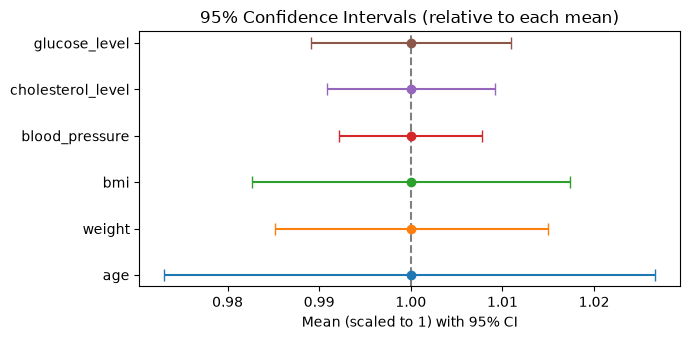

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for i, r in ci_df.iterrows():
    ax.errorbar(r['Mean'] / r['Mean'], i, xerr=[[ (r['Mean']-r['CI Lower'])/r['Mean']], [ (r['CI Upper']-r['Mean'])/r['Mean']]], fmt='o', capsize=4)
ax.set_yticks(range(len(ci_df))); ax.set_yticklabels(ci_df['Variable'])
ax.axvline(1, color='gray', ls='--'); ax.set_xlabel('Mean (scaled to 1) with 95% CI')
ax.set_title('95% Confidence Intervals (relative to each mean)')
plt.tight_layout(); plt.show()

**Interpretation:** All six 95% confidence intervals are very narrow (within about ±3% of their means), so with n = 600 the sample means are precise estimates of the true population means. Blood pressure and cholesterol are estimated most precisely, while age has the widest relative interval because of its larger spread.

## B3 & B8. Hypothesis Tests — Critical Values, p-values, Decisions
### H1 — Chi-square: Smoking vs Diabetes

diabetes        False  True 
smoking_status              
Former Smoker      78     18
Non-Smoker        276     84
Smoker            109     35 

Chi-square = 1.1367 | dof = 2 | critical value = 5.9915 | p-value = 0.566468
Decision: FAIL TO REJECT H0


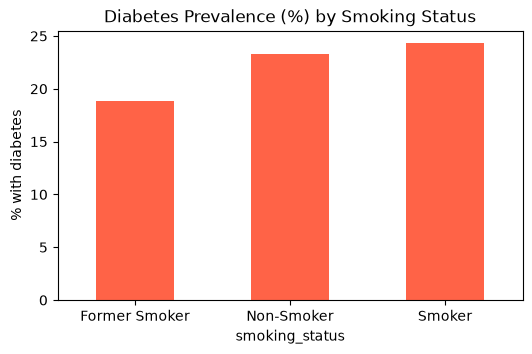

In [6]:
ct = pd.crosstab(df.smoking_status, df.diabetes)
print(ct, '\n')
chi2, p, dof, expected = stats.chi2_contingency(ct)
crit = stats.chi2.ppf(1 - ALPHA, dof)
print(f'Chi-square = {chi2:.4f} | dof = {dof} | critical value = {crit:.4f} | p-value = {p:.6f}')
print('Decision:', 'REJECT H0' if p < ALPHA else 'FAIL TO REJECT H0')
(ct.div(ct.sum(axis=1), axis=0)[True] * 100).round(1).plot(kind='bar', color='tomato', figsize=(6, 3.5), title='Diabetes Prevalence (%) by Smoking Status')
plt.ylabel('% with diabetes'); plt.xticks(rotation=0); plt.show()

**Interpretation:** The chi-square statistic (χ² = 1.14, dof = 2) is below the critical value (5.99) and p = 0.566 > 0.05, so we fail to reject H₀. Diabetes prevalence is similar across smokers (24.3%), non-smokers (23.3%) and former smokers (18.8%), so smoking status is not significantly associated with diabetes in this sample.

### H2 — Welch t-test: Blood Pressure, Smokers vs Non-Smokers

Mean BP Smoker = 110.50, Non-Smoker = 109.14
t = 1.2374 | df = 239.6 | critical value = ±1.9699 | p-value = 0.217139
Decision: FAIL TO REJECT H0


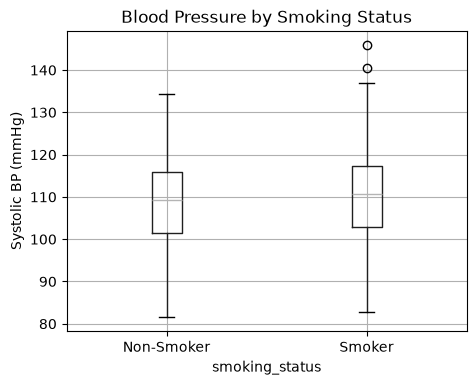

In [7]:
a = df[df.smoking_status == 'Smoker'].blood_pressure
b = df[df.smoking_status == 'Non-Smoker'].blood_pressure
t, p = stats.ttest_ind(a, b, equal_var=False)
dfree = (a.var()/len(a) + b.var()/len(b))**2 / ((a.var()/len(a))**2/(len(a)-1) + (b.var()/len(b))**2/(len(b)-1))
tcrit = stats.t.ppf(1 - ALPHA/2, dfree)
print(f'Mean BP Smoker = {a.mean():.2f}, Non-Smoker = {b.mean():.2f}')
print(f't = {t:.4f} | df = {dfree:.1f} | critical value = ±{tcrit:.4f} | p-value = {p:.6f}')
print('Decision:', 'REJECT H0' if p < ALPHA else 'FAIL TO REJECT H0')
df[df.smoking_status.isin(['Smoker','Non-Smoker'])].boxplot(column='blood_pressure', by='smoking_status', figsize=(5,4))
plt.title('Blood Pressure by Smoking Status'); plt.suptitle(''); plt.ylabel('Systolic BP (mmHg)'); plt.show()

**Interpretation:** |t| = 1.24 is below the critical value ±1.97 and p = 0.217 > 0.05, so we fail to reject H₀. Mean systolic BP is similar for smokers (110.50 mmHg) and non-smokers (109.14 mmHg), and the small difference of about 1.4 mmHg is likely due to chance.

### H3 — Two-sample z-test: BMI, Male vs Female (n large)

In [8]:
m = df[df.gender == 'Male'].bmi; f = df[df.gender == 'Female'].bmi
z = (m.mean() - f.mean()) / np.sqrt(m.var(ddof=1)/len(m) + f.var(ddof=1)/len(f))
p = 2 * (1 - stats.norm.cdf(abs(z)))
zcrit = stats.norm.ppf(1 - ALPHA/2)
print(f'Mean BMI Male = {m.mean():.2f}, Female = {f.mean():.2f}')
print(f'z = {z:.4f} | critical value = ±{zcrit:.4f} | p-value = {p:.6f}')
print('Decision:', 'REJECT H0' if p < ALPHA else 'FAIL TO REJECT H0')

Mean BMI Male = 27.34, Female = 23.23
z = 9.7323 | critical value = ±1.9600 | p-value = 0.000000
Decision: REJECT H0


**Interpretation:** |z| = 9.73 is far above the critical value ±1.96 and p < 0.001, so we reject H₀. Males have a significantly higher mean BMI (27.34) than females (23.23), a difference of about 4.1 BMI units.

### H4 — One-way ANOVA: Diabetes Rate across Age Groups

age_group
18-25     9.8
26-35    14.3
36-45    22.3
46-60    29.7
60+      53.5 

F = 10.9684 | df = (4, 595) | critical value = 2.3869 | p-value = 0.000000
Decision: REJECT H0


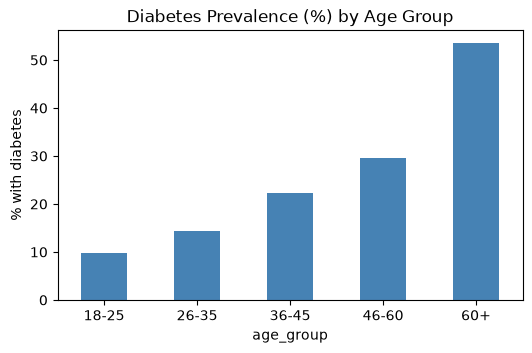

In [9]:
order = ['18-25', '26-35', '36-45', '46-60', '60+']
groups = [df[df.age_group == g].diabetes.astype(int) for g in order]
F, p = stats.f_oneway(*groups)
k, N = len(groups), len(df)
Fcrit = stats.f.ppf(1 - ALPHA, k - 1, N - k)
print((df.groupby('age_group').diabetes.mean().reindex(order) * 100).round(1).to_string(), '\n')
print(f'F = {F:.4f} | df = ({k-1}, {N-k}) | critical value = {Fcrit:.4f} | p-value = {p:.6f}')
print('Decision:', 'REJECT H0' if p < ALPHA else 'FAIL TO REJECT H0')
(df.groupby('age_group').diabetes.mean().reindex(order) * 100).plot(kind='bar', color='steelblue', figsize=(6, 3.5), title='Diabetes Prevalence (%) by Age Group')
plt.ylabel('% with diabetes'); plt.xticks(rotation=0); plt.show()

**Interpretation:** F = 10.97 is above the critical value 2.39 and p < 0.001, so we reject H₀. Diabetes prevalence rises steadily with age, from 9.8% (18-25) to 53.5% (60+), so age group is significantly associated with diabetes.

## B7. Covariance & Correlation

In [10]:
cols = ['age', 'weight', 'bmi', 'blood_pressure', 'cholesterol_level', 'glucose_level']
print('Covariance (Age vs BMI):', round(df.age.cov(df.bmi), 4))
r, p = stats.pearsonr(df.age, df.bmi)
print(f'Pearson r (Age vs BMI) = {r:.4f}, p-value = {p:.6f}')
print('Decision (H5):', 'REJECT H0' if p < ALPHA else 'FAIL TO REJECT H0')
print('\nCovariance matrix:'); display(df[cols].cov().round(2))
print('Correlation matrix:'); display(df[cols].corr().round(3))

Covariance (Age vs BMI): -6.1111
Pearson r (Age vs BMI) = -0.0812, p-value = 0.046713
Decision (H5): REJECT H0

Covariance matrix:


,age,weight,bmi,blood_pressure,cholesterol_level,glucose_level
age,188.11,-6.69,-6.11,53.40,117.65,56.00
weight,-6.69,179.64,62.64,33.34,79.49,46.89
bmi,-6.11,62.64,30.09,8.81,36.47,22.26
blood_pressure,53.40,33.34,8.81,113.50,41.72,21.55
cholesterol_level,117.65,79.49,36.47,41.72,409.50,67.21
glucose_level,56.00,46.89,22.26,21.55,67.21,147.35


Correlation matrix:


,age,weight,bmi,blood_pressure,cholesterol_level,glucose_level
age,1.000,-0.036,-0.081,0.365,0.424,0.336
weight,-0.036,1.000,0.852,0.234,0.293,0.288
bmi,-0.081,0.852,1.000,0.151,0.329,0.334
blood_pressure,0.365,0.234,0.151,1.000,0.194,0.167
cholesterol_level,0.424,0.293,0.329,0.194,1.000,0.274
glucose_level,0.336,0.288,0.334,0.167,0.274,1.000


**Interpretation:** Age vs BMI has a covariance of −6.11 and r = −0.081 (p = 0.047 < 0.05), so we reject H₀, but only narrowly. The relationship is very weak (r² ≈ 0.7%), so age explains almost none of the variation in BMI. In the matrices, BP, cholesterol and glucose correlate moderately and positively with age (r ≈ 0.34–0.42), and weight and BMI are strongly correlated (r ≈ 0.85).

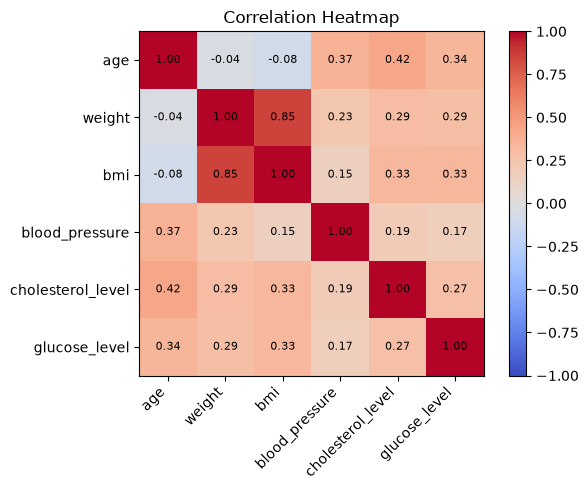

In [11]:
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha='right'); ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)): ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im); ax.set_title('Correlation Heatmap'); plt.tight_layout(); plt.show()

**Interpretation:** The heatmap shows that weight and BMI are strongly positively correlated (r ≈ 0.85), as expected since BMI is calculated from weight. Age has moderate positive correlations with cholesterol (0.42), BP (0.37) and glucose (0.34), while age vs BMI is almost zero (−0.08) and all other pairs are weak to moderate positive..

## Final Summary of Judgements

In [12]:
summary = pd.DataFrame([
 ['H1 Smoking vs Diabetes', 'Chi-square', 'REJECT H0' if stats.chi2_contingency(pd.crosstab(df.smoking_status, df.diabetes))[1] < ALPHA else 'FAIL TO REJECT H0'],
 ['H2 BP: Smoker vs Non-Smoker', 'Welch t-test', 'REJECT H0' if stats.ttest_ind(a, b, equal_var=False)[1] < ALPHA else 'FAIL TO REJECT H0'],
 ['H3 BMI: Male vs Female', 'z-test', 'REJECT H0' if 2*(1-stats.norm.cdf(abs(z))) < ALPHA else 'FAIL TO REJECT H0'],
 ['H4 Diabetes across age groups', 'ANOVA', 'REJECT H0' if stats.f_oneway(*groups)[1] < ALPHA else 'FAIL TO REJECT H0'],
 ['H5 Age vs BMI correlation', 'Pearson', 'REJECT H0' if stats.pearsonr(df.age, df.bmi)[1] < ALPHA else 'FAIL TO REJECT H0'],
], columns=['Hypothesis', 'Test', 'Decision (α=0.05)'])
summary

,Hypothesis,Test,Decision (α=0.05)
0,H1 Smoking vs Diabetes,Chi-square,FAIL TO REJECT H0
1,H2 BP: Smoker vs Non-Smoker,Welch t-test,FAIL TO REJECT H0
2,H3 BMI: Male vs Female,z-test,REJECT H0
3,H4 Diabetes across age groups,ANOVA,REJECT H0
4,H5 Age vs BMI correlation,Pearson,REJECT H0


**Conclusion:** At α = 0.05, age is the clearest driver of diabetes (prevalence rises from about 10% to 54%), and males have a significantly higher BMI than females (27.3 vs 23.2). Smoking shows no significant link with diabetes or blood pressure, and age vs BMI is only very weakly correlated (r ≈ −0.08). These are associations in the sample, not proof of causation.